## Social Media Engagement Analytics Using Python

In [2]:
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"

df = pd.read_csv(url)

# Display first five rows
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [3]:
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
print("Column names:")
print(df.columns.tolist())

Dataset loaded successfully!
Number of rows and columns: (5000, 19)
Column names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [4]:
# Display data types before conversion
print("Data types before conversion:")
print(df.dtypes)

# Convert date column into datetime format
df["posted_at"] = pd.to_datetime(
    df["posted_at"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Convert numeric columns
numeric_columns = [
    "age", "likes", "comments", "shares",
    "watch_time_sec", "impression_count",
    "follower_count", "engagement_rate"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert verified column to a consistent boolean format
df["is_verified"] = (
    df["is_verified"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
)

print("\nData types after conversion:")
print(df.dtypes)

Data types before conversion:
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

Data types after conversion:
user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impressio

In [5]:
# Convert likes into a NumPy array
likes_array = df["likes"].dropna().to_numpy()

print("First 10 likes:", likes_array[:10])
print("Total likes:", np.sum(likes_array))
print("Average likes:", np.mean(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Minimum likes:", np.min(likes_array))

First 10 likes: [ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611. 14106.   355.]
Total likes: 49019162.0
Average likes: 10107.043711340206
Maximum likes: 19998.0
Minimum likes: 10.0


In [6]:
print("Missing values using isnull():")
print(df.isnull().sum())

print("\nMissing values using isna():")
print(df.isna().sum())

print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values using isnull():
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Missing values using isna():
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64



In [7]:
# Remove rows missing essential information
df = df.dropna(subset=["post_id", "posted_at"])

# Fill missing numerical values using the median
numeric_columns = df.select_dtypes(include="number").columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values using the mode
categorical_columns = [
    "gender", "country", "post_type", "post_category",
    "is_verified", "device_type", "sentiment"
]

for col in categorical_columns:
    if df[col].isna().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing hashtags with an empty string
df["hashtags"] = df["hashtags"].fillna("")

# Forward-fill and backward-fill remaining date gaps, if any
df["posted_at"] = df["posted_at"].ffill().bfill()

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [8]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape after cleaning:", df.shape)

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Dataset shape after cleaning: (5000, 19)


In [9]:
# Standardize text categories
text_columns = [
    "gender", "country", "post_type",
    "post_category", "device_type", "sentiment"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip().str.lower()

# Standardize sentiment labels
df["sentiment"] = df["sentiment"].replace({
    "pos": "positive",
    "neg": "negative",
    "neu": "neutral"
})

# Standardize boolean values
print(df[text_columns].head())
print("\nGender categories:", df["gender"].unique())
print("Sentiment categories:", df["sentiment"].unique())

   gender country post_type post_category device_type sentiment
0  female  brazil     image       fitness      mobile  negative
1    male  brazil      reel          food      mobile  negative
2  female      uk      text          food      tablet  positive
3   other  france      text       fitness      mobile  negative
4   other      uk     image       fitness      mobile  negative

Gender categories: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: string
Sentiment categories: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: string


In [10]:
# Check for unrealistic values
print("Negative ages:", (df["age"] < 0).sum())
print("Negative likes:", (df["likes"] < 0).sum())
print("Negative comments:", (df["comments"] < 0).sum())
print("Negative shares:", (df["shares"] < 0).sum())
print("Negative watch time:", (df["watch_time_sec"] < 0).sum())
print("Negative impressions:", (df["impression_count"] < 0).sum())
print("Negative followers:", (df["follower_count"] < 0).sum())

# Replace impossible negative metric values with NaN
metric_columns = [
    "likes", "comments", "shares",
    "watch_time_sec", "impression_count",
    "follower_count", "engagement_rate"
]

for col in metric_columns:
    df.loc[df[col] < 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

# Keep only plausible ages
df.loc[~df["age"].between(0, 120), "age"] = np.nan
df["age"] = df["age"].fillna(df["age"].median())

print("Unrealistic values checked and handled.")

Negative ages: 0
Negative likes: 0
Negative comments: 0
Negative shares: 0
Negative watch time: 0
Negative impressions: 0
Negative followers: 0
Unrealistic values checked and handled.


In [11]:
# Count hashtags in each post
df["hashtag_count"] = df["hashtags"].apply(
    lambda x: len(str(x).split())
)

df[["hashtags", "hashtag_count"]].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [12]:
# Clean sentiment text
df["sentiment"] = (
    df["sentiment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Display cleaned sentiment labels
print(df["sentiment"].value_counts())
print("\nUnique sentiment labels:", df["sentiment"].unique())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64[pyarrow]

Unique sentiment labels: <ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: string


In [13]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

First five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726.0,44650.0,2022-12-17,81734.0,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947.0,80216.0,2023-06-02,5963.0,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946.0,44858.0,2023-05-07,501783.0,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229.0,70455.0,2023-02-12,480212.0,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798.0,6019.0,2023-05-23,383936.0,False,mobile,negative,#travel,2.777372,1


Last five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190.0,42977.0,2022-06-25,646147.0,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764.0,34196.0,2022-11-18,584603.0,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,1497.0,167.0,7466.0,23680.0,2023-04-06,483550.0,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991.0,89013.0,2022-05-16,183295.0,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743.0,14234.0,2023-03-04,585760.0,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


Dataset shape: (5000, 20)

Column names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [14]:
df.info()

print("\nData types:")
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   string        
 3   country           5000 non-null   string        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   string        
 6   post_category     5000 non-null   string        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   float64       
 11  impression_count  5000 non-null   float64       
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   float64       
 14  is_verified       5000 non-null   b

In [15]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [16]:
# Distribution of post types
print("Post type counts:")
print(df["post_type"].value_counts())

# Unique countries
print("\nCountries:")
print(df["country"].unique())

# Number of unique countries
print("\nNumber of unique countries:", df["country"].nunique())

# Sentiment distribution
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

Post type counts:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64[pyarrow]

Countries:
<ArrowStringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: string

Number of unique countries: 10

Sentiment counts:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64[pyarrow]


In [17]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

display(correlation_matrix)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [18]:
# Average likes by post type
print("Average likes by post type:")
display(df.groupby("post_type", observed=True)["likes"].mean().sort_values(ascending=False))

# Average impressions by country
print("Average impressions by country:")
display(df.groupby("country", observed=True)["impression_count"].mean().sort_values(ascending=False))

# Average engagement rate by category
print("Average engagement rate by category:")
display(df.groupby("post_category", observed=True)["engagement_rate"].mean().sort_values(ascending=False))

Average likes by post type:


post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64

Average impressions by country:


country
india        52462.386916
france       51727.673387
usa          51263.872255
uk           51119.393509
japan        49616.135593
brazil       49193.174603
uae          48928.413519
canada       48703.150097
germany      48605.406122
australia    48346.383367
Name: impression_count, dtype: float64

Average engagement rate by category:


post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

In [19]:
# Calculate engagement score
df["engagement_score"] = (
    df["likes"] + df["comments"] + df["shares"]
)

# Extract posting hour
df["posting_hour"] = df["posted_at"].dt.hour

# Extract posting date
df["posting_date"] = df["posted_at"].dt.date

# Create log-transformed metrics
df["log_likes"] = np.log1p(df["likes"])
df["log_impressions"] = np.log1p(df["impression_count"])

display(df[[
    "likes", "comments", "shares",
    "engagement_score", "hashtag_count",
    "posting_hour", "log_likes"
]].head())

,likes,comments,shares,engagement_score,hashtag_count,posting_hour,log_likes
0,7011.0,354.0,1157.0,8522.0,3,0,8.855378
1,11750.0,2606.0,1807.0,16163.0,1,0,9.371694
2,4862.0,344.0,955.0,6161.0,1,0,8.489411
3,5350.0,1083.0,1049.0,7482.0,3,0,8.585039
4,12682.0,2735.0,1300.0,16717.0,1,0,9.448018


In [20]:
# Summary by post type
post_type_summary = df.groupby(
    "post_type", observed=True
).agg(
    total_posts=("post_id", "count"),
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    average_engagement_rate=("engagement_rate", "mean")
).round(2)

display(post_type_summary)

,total_posts,average_likes,average_comments,average_shares,average_engagement_rate
post_type,,,,,
image,1247,10104.87,1525.24,1019.29,0.90
reel,1283,10037.80,1504.19,982.04,0.78
text,1245,10100.15,1499.11,1013.99,1.06
video,1225,10188.60,1479.16,996.83,1.12


In [21]:
# Summary by country
country_summary = df.groupby(
    "country", observed=True
).agg(
    total_posts=("post_id", "count"),
    average_impressions=("impression_count", "mean"),
    average_engagement_rate=("engagement_rate", "mean")
).round(2).sort_values(
    "average_engagement_rate", ascending=False
)

display(country_summary)

,total_posts,average_impressions,average_engagement_rate
country,,,
brazil,504,49193.17,1.54
australia,493,48346.38,1.32
france,496,51727.67,1.15
uae,503,48928.41,1.11
canada,513,48703.15,0.92
uk,493,51119.39,0.85
japan,472,49616.14,0.77
germany,490,48605.41,0.76
india,535,52462.39,0.66


In [22]:
# Summary by sentiment
sentiment_summary = df.groupby(
    "sentiment", observed=True
).agg(
    total_posts=("post_id", "count"),
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    average_engagement_rate=("engagement_rate", "mean")
).round(2)

display(sentiment_summary)

,total_posts,average_likes,average_comments,average_shares,average_engagement_rate
sentiment,,,,,
negative,960,10208.10,1516.09,1007.31,1.04
neutral,1527,9923.19,1528.40,996.57,0.99
positive,2513,10180.06,1480.65,1005.09,0.92


In [23]:
first_part = df.iloc[:100].copy()
second_part = df.iloc[100:200].copy()

combined_df = pd.concat(
    [first_part, second_part],
    ignore_index=True
)

print("First part shape:", first_part.shape)
print("Second part shape:", second_part.shape)
print("Combined shape:", combined_df.shape)

display(combined_df.head())

First part shape: (100, 25)
Second part shape: (100, 25)
Combined shape: (200, 25)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,device_type,sentiment,hashtags,engagement_rate,hashtag_count,engagement_score,posting_hour,posting_date,log_likes,log_impressions
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,...,mobile,negative,#foodie #travel #love,0.190862,3,8522.0,0,2022-12-17,8.855378,10.706632
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,...,mobile,negative,#fitness,0.201493,1,16163.0,0,2023-06-02,9.371694,11.292491
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,...,tablet,positive,#foodie,0.137345,1,6161.0,0,2023-05-07,8.489411,10.711280
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,...,mobile,negative,#music #foodie #fun,0.106195,3,7482.0,0,2023-02-12,8.585039,11.162744
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,...,mobile,negative,#travel,2.777372,1,16717.0,0,2023-05-23,9.448018,8.702843


In [24]:
stats_columns = [
    "likes", "comments", "shares",
    "watch_time_sec", "engagement_rate",
    "follower_count"
]

for col in stats_columns:
    print(f"\nStatistics for {col}")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().tolist()[:5])


Statistics for likes
Mean: 10106.9974
Median: 10105.5
Mode: [10105.5]

Statistics for comments
Mean: 1502.0398
Median: 1497.0
Mode: [1497.0]

Statistics for shares
Mean: 1002.9106
Median: 1012.0
Mode: [1012.0]

Statistics for watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: [916.0, 2145.0, 4360.0, 7003.0, 7688.0]

Statistics for engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: [0.006362909, 0.007420223, 0.012675682, 0.012692458, 0.015004762]

Statistics for follower_count
Mean: 393698.2248
Median: 388982.0
Mode: [497502.0]


In [25]:
for col in stats_columns:
    print(f"\n{col}")
    print("Standard deviation:", df[col].std())
    print("Variance:", df[col].var())


likes
Standard deviation: 5702.293017183877
Variance: 32516145.65382401

comments
Standard deviation: 856.3933120458984
Variance: 733409.5049169434

shares
Standard deviation: 570.8551999758852
Variance: 325875.65933950787

watch_time_sec
Standard deviation: 2308.0964590420845
Variance: 5327309.264242608

engagement_rate
Standard deviation: 5.31802922266154
Variance: 28.281434813082104

follower_count
Standard deviation: 230927.88453461003
Variance: 53327687855.63019


In [26]:
percentiles = df[stats_columns].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95]
)

display(percentiles)

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.00,792.00,511.00,2017.75,0.145781,194480.00
0.50,10105.50,1497.00,1012.00,4034.50,0.253896,388982.00
0.75,14959.00,2235.25,1483.00,6020.25,0.504794,589744.25
0.90,18016.30,2695.10,1795.10,7212.10,1.201200,717755.90
0.95,19097.05,2861.00,1901.05,7577.05,2.328526,760174.35


In [27]:
print("Skewness:")
display(df[stats_columns].skew())

print("Kurtosis:")
display(df[stats_columns].kurtosis())

Skewness:


likes              -0.006894
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64

Kurtosis:


likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64

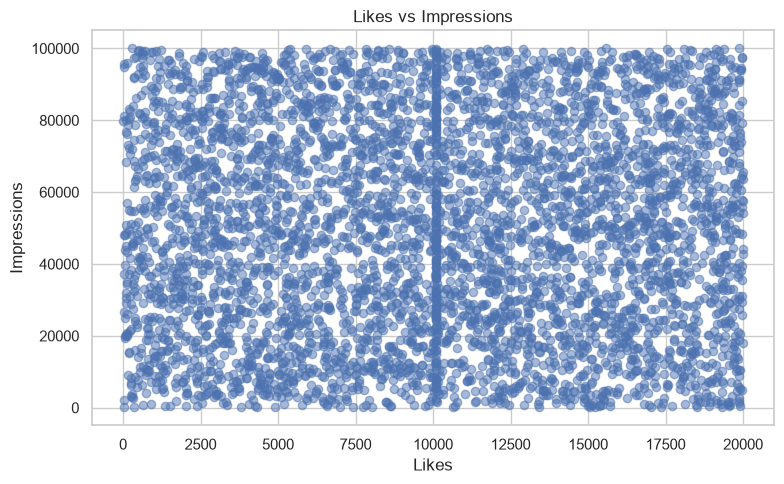

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(df["likes"], df["impression_count"], alpha=0.5)

plt.title("Likes vs Impressions")
plt.xlabel("Likes")
plt.ylabel("Impressions")
plt.tight_layout()
plt.show()

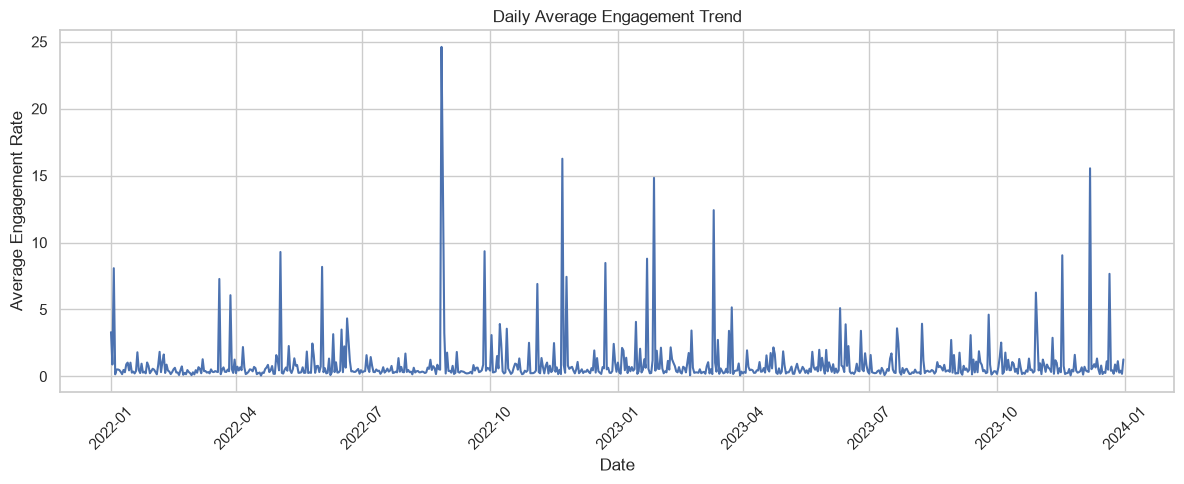

In [29]:
daily_engagement = df.groupby(
    "posting_date"
)["engagement_rate"].mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.title("Daily Average Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

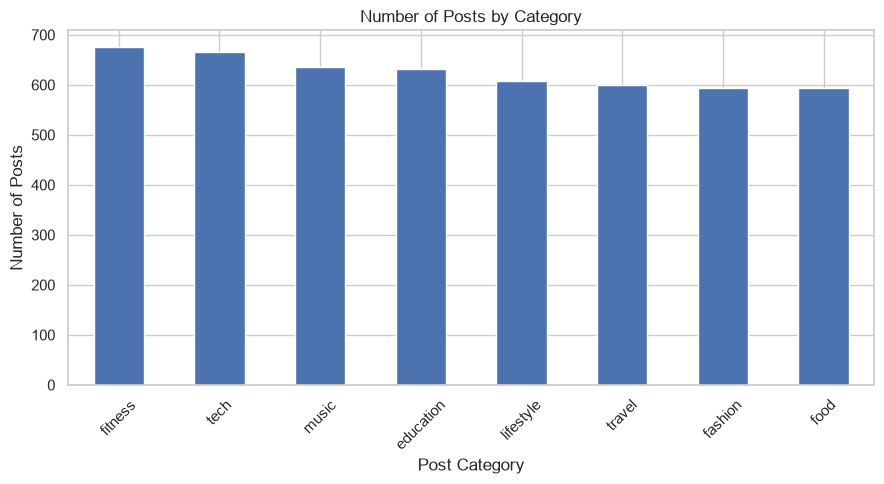

In [30]:
category_counts = df["post_category"].value_counts()

plt.figure(figsize=(9, 5))

category_counts.plot(kind="bar")

plt.title("Number of Posts by Category")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

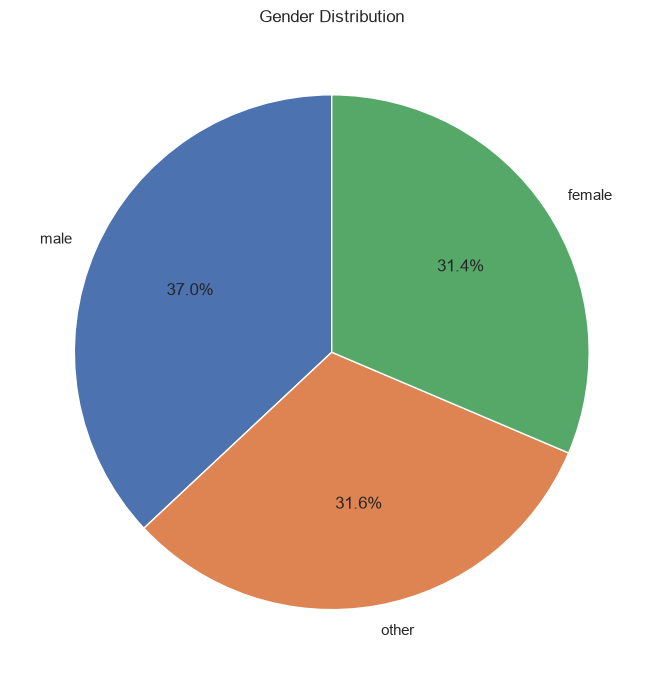

In [31]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

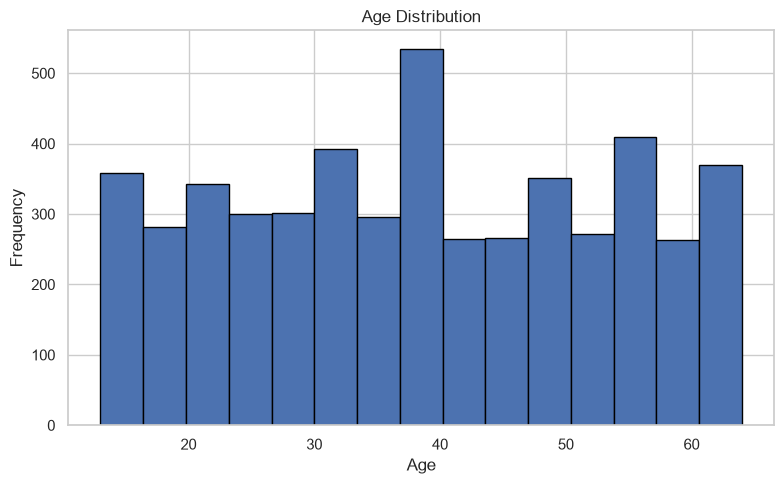

In [32]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=15, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

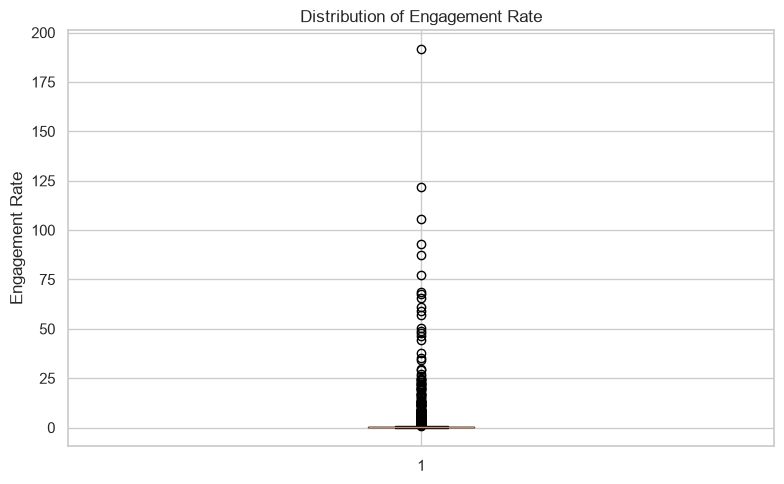

In [34]:
plt.figure(figsize=(8, 5))

plt.boxplot(df["engagement_rate"].dropna())

plt.title("Distribution of Engagement Rate")
plt.ylabel("Engagement Rate")
plt.tight_layout()
plt.show()

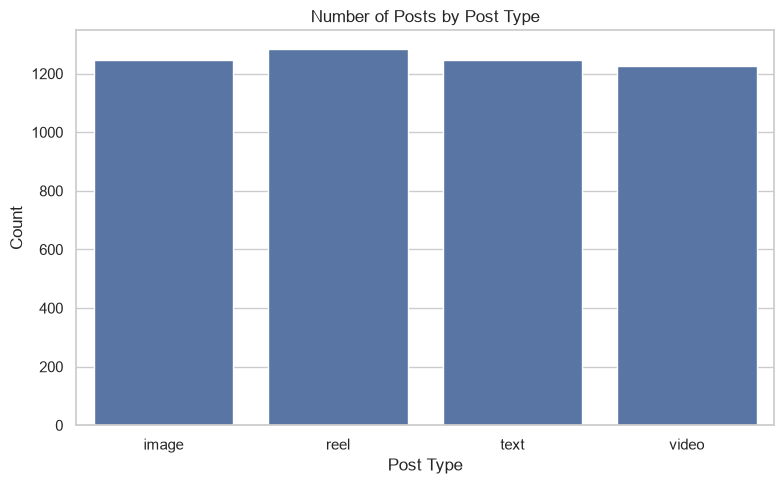

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="post_type")

plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

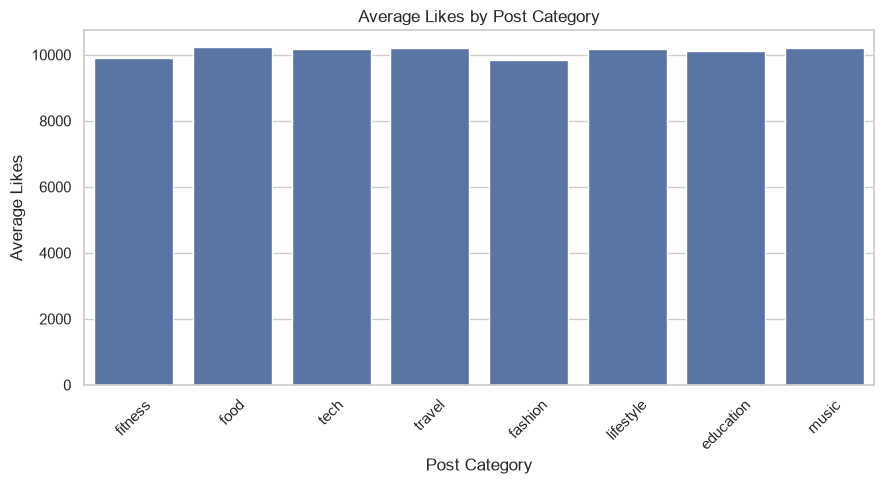

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="post_category",
    y="likes",
    errorbar=None
)

plt.title("Average Likes by Post Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

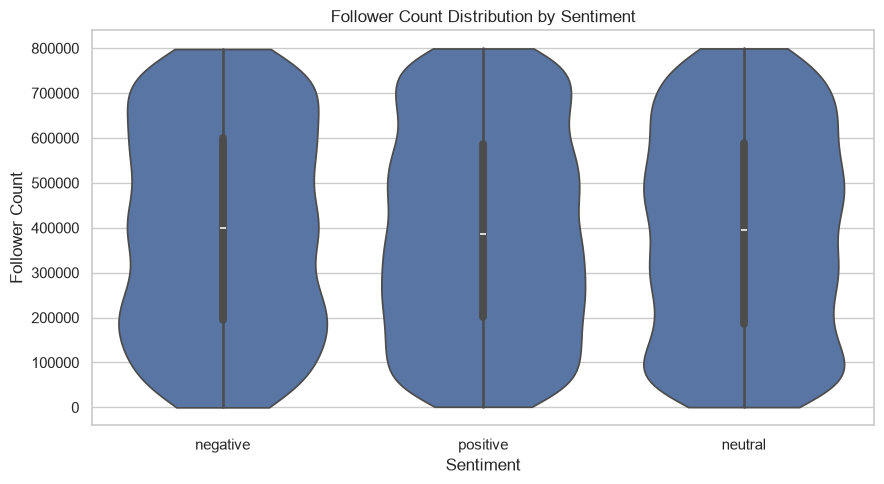

In [37]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count",
    cut=0
)

plt.title("Follower Count Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.tight_layout()
plt.show()

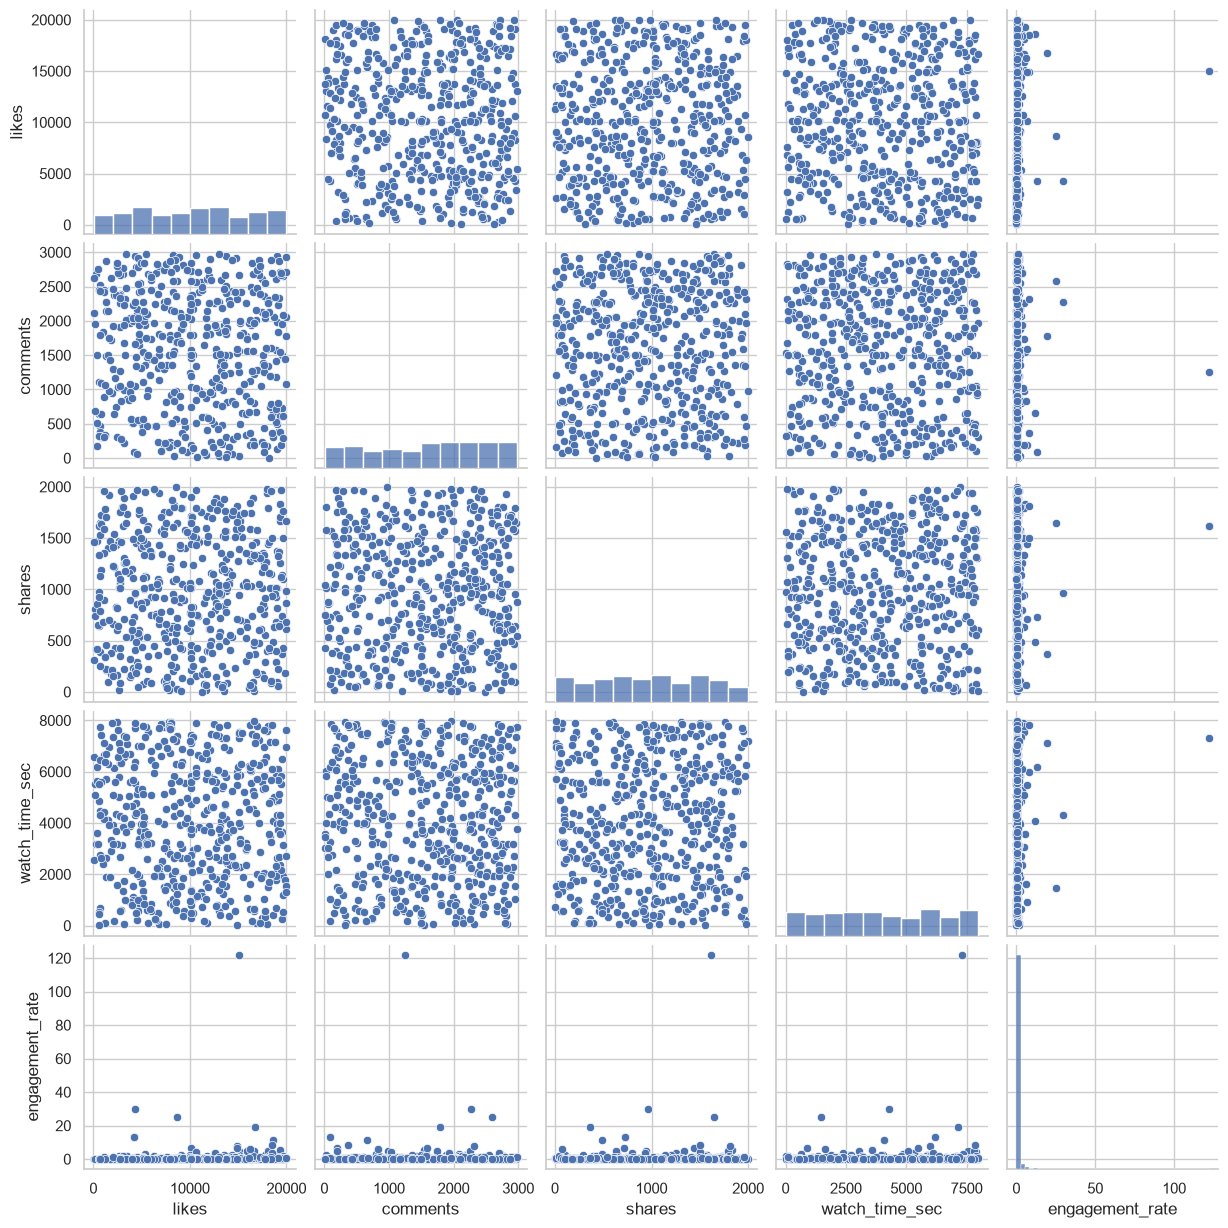

In [38]:
pair_columns = [
    "likes", "comments", "shares",
    "watch_time_sec", "engagement_rate"
]

pair_data = df[pair_columns].dropna()

# Sample a maximum of 500 rows for readability
if len(pair_data) > 500:
    pair_data = pair_data.sample(500, random_state=42)

sns.pairplot(pair_data)

plt.show()

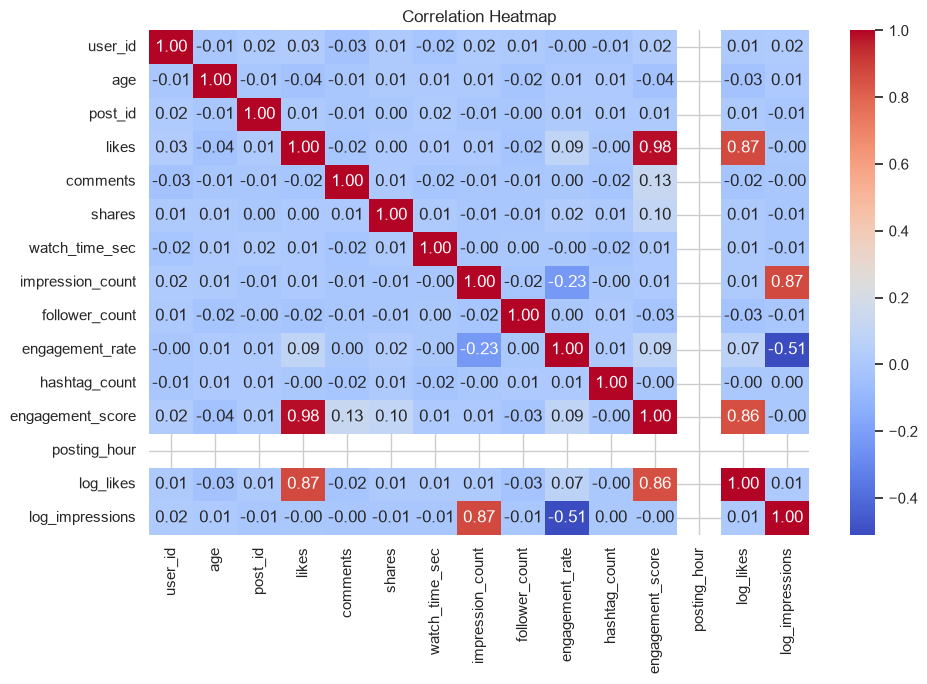

In [39]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

C:\Users\zinee\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 8.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\zinee\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 30.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\zinee\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 25.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\zinee\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 19.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\zinee\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 38.9% of the points 

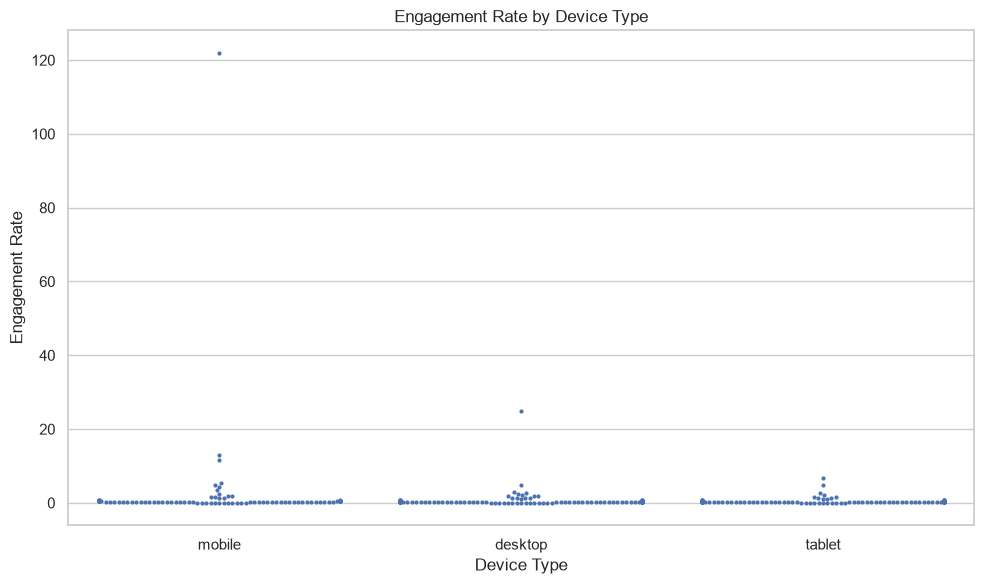

In [40]:
swarm_data = df[
    ["device_type", "engagement_rate"]
].dropna()

if len(swarm_data) > 300:
    swarm_data = swarm_data.sample(300, random_state=42)

plt.figure(figsize=(10, 6))

sns.swarmplot(
    data=swarm_data,
    x="device_type",
    y="engagement_rate",
    size=3
)

plt.title("Engagement Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.tight_layout()
plt.show()

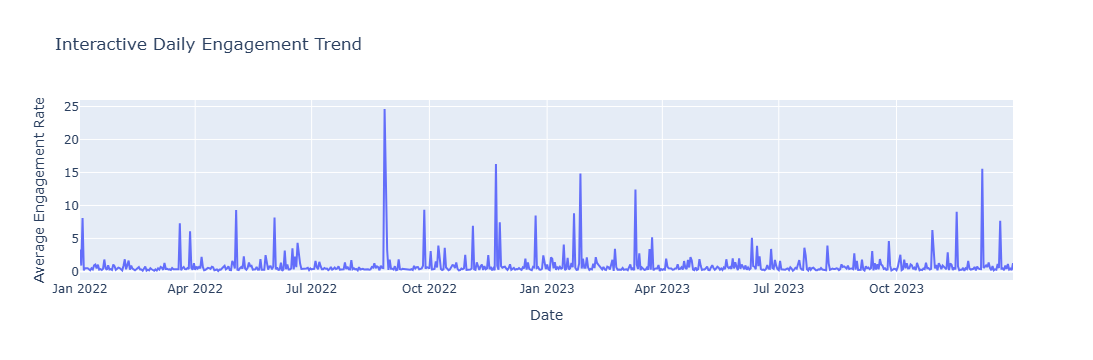

In [41]:
daily_data = df.groupby(
    "posting_date", as_index=False
)["engagement_rate"].mean()

fig = px.line(
    daily_data,
    x="posting_date",
    y="engagement_rate",
    title="Interactive Daily Engagement Trend",
    labels={
        "posting_date": "Date",
        "engagement_rate": "Average Engagement Rate"
    }
)

fig.show()

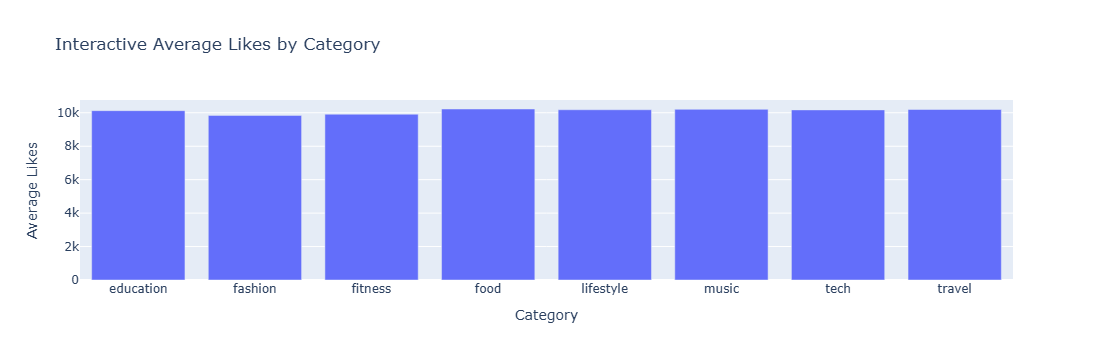

In [42]:
interactive_category = df.groupby(
    "post_category", as_index=False
)["likes"].mean()

fig = px.bar(
    interactive_category,
    x="post_category",
    y="likes",
    title="Interactive Average Likes by Category",
    labels={
        "post_category": "Category",
        "likes": "Average Likes"
    }
)

fig.show()

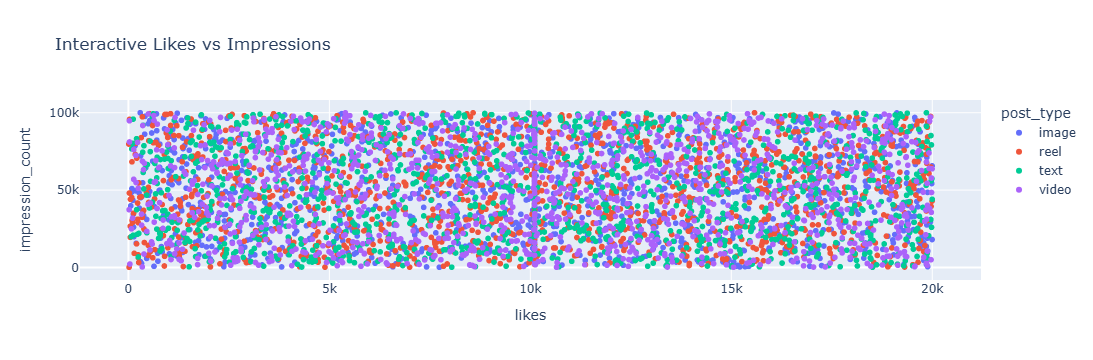

In [43]:
fig = px.scatter(
    df,
    x="likes",
    y="impression_count",
    color="post_type",
    hover_data=["country", "post_category"],
    title="Interactive Likes vs Impressions"
)

fig.show()

In [44]:
# Which post types have the highest engagement?
post_performance = df.groupby(
    "post_type", observed=True
).agg(
    avg_engagement=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean")
).sort_values("avg_engagement", ascending=False)

print("Post type performance:")
display(post_performance)

print("Best-performing post type:")
print(post_performance["avg_engagement"].idxmax())

# Best-performing content category
category_performance = df.groupby(
    "post_category", observed=True
)["engagement_rate"].mean().sort_values(ascending=False)

display(category_performance)

print("Best-performing category:")
print(category_performance.idxmax())

Post type performance:


,avg_engagement,avg_likes,avg_comments,avg_shares
post_type,,,,
video,1.122365,10188.600000,1479.160000,996.834286
text,1.064549,10100.148193,1499.106024,1013.989558
image,0.895646,10104.865277,1525.235766,1019.289495
reel,0.783047,10037.802416,1504.187062,982.042089


Best-performing post type:
video


post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Best-performing category:
food


In [45]:
country_performance = df.groupby(
    "country", observed=True
)["engagement_rate"].mean().sort_values(ascending=False)

display(country_performance)

print("Country with the highest average engagement rate:")
print(country_performance.idxmax())

country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64

Country with the highest average engagement rate:
brazil


In [46]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 17, 25, 35, 45, 60, 120],
    labels=[
        "Under 18", "18-25", "26-35",
        "36-45", "46-60", "Above 60"
    ]
)

age_performance = df.groupby(
    "age_group", observed=True
)["engagement_rate"].mean().sort_values(ascending=False)

display(age_performance)

print("Age group with the highest average engagement:")
print(age_performance.idxmax())

age_group
46-60       1.152669
18-25       1.036932
26-35       0.865316
Under 18    0.862367
36-45       0.860741
Above 60    0.801381
Name: engagement_rate, dtype: float64

Age group with the highest average engagement:
46-60


In [47]:
verified_performance = df.groupby(
    "is_verified", observed=True
).agg(
    average_engagement=("engagement_rate", "mean"),
    average_likes=("likes", "mean"),
    average_impressions=("impression_count", "mean"),
    post_count=("post_id", "count")
)

display(verified_performance)

,average_engagement,average_likes,average_impressions,post_count
is_verified,,,,
False,0.954744,10137.201129,49935.288244,4517
True,1.054250,9824.533126,50747.343685,483


In [48]:
hourly_impressions = df.groupby(
    "posting_hour"
)["impression_count"].mean().sort_values(ascending=False)

display(hourly_impressions)

best_hour = hourly_impressions.idxmax()

print("Best posting hour based on average impressions:", best_hour)

posting_hour
0    50013.7328
Name: impression_count, dtype: float64

Best posting hour based on average impressions: 0


In [49]:
device_performance = df.groupby(
    "device_type", observed=True
).agg(
    average_watch_time=("watch_time_sec", "mean"),
    average_engagement=("engagement_rate", "mean"),
    average_impressions=("impression_count", "mean")
).sort_values("average_watch_time", ascending=False)

display(device_performance)

print("Device with the highest average watch time:")
print(device_performance["average_watch_time"].idxmax())

,average_watch_time,average_engagement,average_impressions
device_type,,,
mobile,4087.830760,1.123999,49516.948931
tablet,3979.736429,0.804560,49597.971049
desktop,3974.792521,0.962006,50934.068758


Device with the highest average watch time:
mobile


In [50]:
sentiment_performance = df.groupby(
    "sentiment", observed=True
).agg(
    average_engagement=("engagement_rate", "mean"),
    average_likes=("likes", "mean"),
    average_comments=("comments", "mean"),
    average_shares=("shares", "mean"),
    post_count=("post_id", "count")
).sort_values("average_engagement", ascending=False)

display(sentiment_performance)

print("Best-performing sentiment:")
print(sentiment_performance["average_engagement"].idxmax())

,average_engagement,average_likes,average_comments,average_shares,post_count
sentiment,,,,,
negative,1.038486,10208.096875,1516.094792,1007.307292,960
neutral,0.991170,9923.194499,1528.404060,996.565160,1527
positive,0.919744,10180.062077,1480.650617,1005.086749,2513


Best-performing sentiment:
negative
